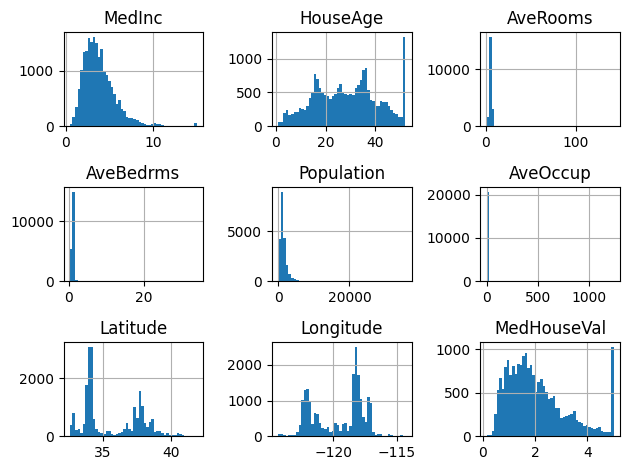

In [8]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

CH=fetch_california_housing()
df_california=pd.DataFrame(CH.data,columns=CH.feature_names)
df_california[CH.target_names[0]]=CH.target
df_california.hist(bins=50)
plt.tight_layout()

**Entrenamiento de un modelo de regresiòn lineal**

1. Separamos las variables de entrenamiento ($X$, $Y$) de las de prueba ($x$, $y$).
2. Compensamos el sesgo de las variables de entrenamiento $X$ y $Y$.
3. Entrenamos el modelo.
4. Evaluamos el score aplicando previamente las transformaciones de compensación de sesgo para $x$ y $y$.

**Predicción**

1. Aplicamos la transformación obtenida en el entrenamiento para $X$.
2. Evaluamos el modelo obtenido.
3. Aplicamos la transformación inversa obtenida en el entrenamiento para $Y$.

In [13]:
# Separamos los datos para usar en el entrenamiento
X,x,Y,y=train_test_split(df_california.drop(columns=[CH.target_names[0],'Latitude','Longitude']),df_california[CH.target_names[0]],test_size=0.2)

# Obtenemos los sesgos a compensar (no los necesitamos :D)
X.skew(),Y.skew()

(MedInc         1.631925
 HouseAge       0.057294
 AveRooms      21.193807
 AveBedrms     30.870906
 Population     4.710112
 AveOccup      98.847592
 dtype: float64,
 np.float64(0.9800339183080771))

# Función logaritmo

In [10]:
# Aplicamos la función logaritmo
#
# Tenemos como restricción que las variables trasformadas sean estrictamente positivas. Es una buena práctica hacer que el mínimo de éstas sea 1
X=X-X.min()+1
X.min()

,0
MedInc,1.0
HouseAge,1.0
AveRooms,1.0
AveBedrms,1.0
Population,1.0
AveOccup,1.0


In [16]:
Y=Y-Y.min()+1
X_compensada=pd.DataFrame(np.log(X),columns=X.columns)            # logaritmo natural
Y_compensada=pd.DataFrame(np.log(Y),columns=[CH.target_names[0]]) # igual

X_compensada.skew(),Y_compensada.skew()

(MedInc       -0.152562
 HouseAge     -1.288259
 AveRooms      0.989119
 AveBedrms     6.499199
 Population   -1.067871
 AveOccup      2.116324
 dtype: float64,
 MedHouseVal    0.240523
 dtype: float64)

array([[<Axes: title={'center': 'MedInc'}>,
        <Axes: title={'center': 'HouseAge'}>],
       [<Axes: title={'center': 'AveRooms'}>,
        <Axes: title={'center': 'AveBedrms'}>],
       [<Axes: title={'center': 'Population'}>,
        <Axes: title={'center': 'AveOccup'}>]], dtype=object)

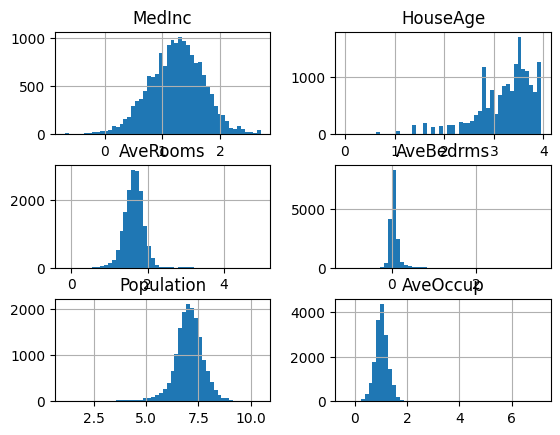

In [17]:
X_compensada.hist(bins=50)

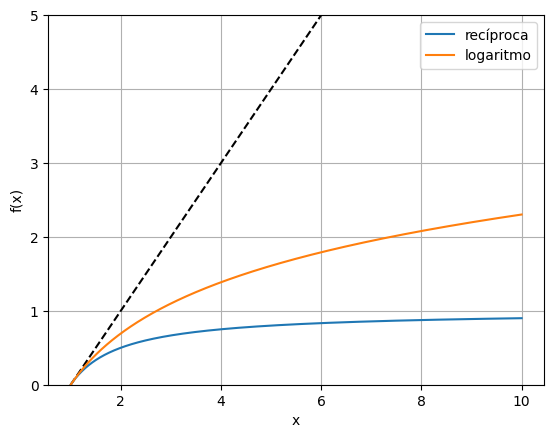

In [20]:
# Cómo se ve la función recíproca con respecto al logaritmo
var=np.linspace(1,10,1000)
plt.plot(var,var-1,'--k')
plt.plot(var,-1/var+1,label='recíproca')
plt.plot(var,np.log(var),label='logaritmo')
plt.legend()
plt.xlabel('x')
plt.ylabel('f(x)')
plt.ylim([0,5])
plt.grid()

Note que, los valores mapeados de ambas transformaciones tienen como valor mínimo cero y crecen conforme crece $x$. Específicamente para la función recíproca, los valores tienen como dominio $[0,1)$, por lo que, la función recíproca aplicada al rango de valores $[0,1)$ mapea de regreso a la variable original (es el inverso pueh), así que la misma función compensa sesgos negativos en valores de rango diferentes.

# Función Recíproca

In [21]:
# Para que los valores mapeados estén entre 0 y 1, aplicamos la función f(x)=-1/x+1
X_reciproco=-1/X+1
X.skew(),X_reciproco.skew()

(MedInc         1.631925
 HouseAge       0.057294
 AveRooms      21.193807
 AveBedrms     30.870906
 Population     4.710112
 AveOccup      98.847592
 dtype: float64,
 MedInc        -2.446314
 HouseAge      -5.610764
 AveRooms      -2.218630
 AveBedrms      1.238969
 Population   -33.478895
 AveOccup      -0.932341
 dtype: float64)

In [24]:
# Comparación de sesgos
sesgos_X=pd.concat([X.skew(),X_compensada.skew(),X_reciproco.skew()],axis=1).rename(columns={0:'original',1:'logaritmo',2:'recíproco'})
sesgos_X

,original,logaritmo,recíproco
MedInc,1.631925,-0.152562,-2.446314
HouseAge,0.057294,-1.288259,-5.610764
AveRooms,21.193807,0.989119,-2.218630
AveBedrms,30.870906,6.499199,1.238969
Population,4.710112,-1.067871,-33.478895
AveOccup,98.847592,2.116324,-0.932341


In [25]:
# Obtener una función que, al evaluar X, regrese los sesgos mínimos en valor absoluto
sesgos_X.abs().min(axis=1)

,0
MedInc,0.152562
HouseAge,0.057294
AveRooms,0.989119
AveBedrms,1.238969
Population,1.067871
AveOccup,0.932341


In [26]:
f={0:lambda x:x,
   1:lambda x:np.log(x),
   2:lambda x:-1/x+1}

In [28]:
np.argmin(sesgos_X.abs(),axis=1)

array([1, 0, 1, 2, 1, 2])

In [30]:
for var,i in zip(X.columns,np.argmin(sesgos_X.abs(),axis=1)):
  X_compensada[var]=f[i](X[var])
X_compensada.skew()

,0
MedInc,-0.152562
HouseAge,0.057294
AveRooms,0.989119
AveBedrms,1.238969
Population,-1.067871
AveOccup,-0.932341


# Regresión lineal